## Part I: Data Pre-processing

In [ ]:
import pandas as pd

In [ ]:
# Download the Google Analogy dataset
!wget http://download.tensorflow.org/data/questions-words.txt

zsh:1: command not found: wget


In [ ]:
# Preprocess the dataset
file_name = "questions-words"
with open(f"{file_name}.txt", "r") as f:
    data = f.read().splitlines()

In [ ]:
# check data from the first 10 entries
for entry in data[:10]:
    print(entry)

: capital-common-countries
Athens Greece Baghdad Iraq
Athens Greece Bangkok Thailand
Athens Greece Beijing China
Athens Greece Berlin Germany
Athens Greece Bern Switzerland
Athens Greece Cairo Egypt
Athens Greece Canberra Australia
Athens Greece Hanoi Vietnam
Athens Greece Havana Cuba


In [ ]:
# TODO1: Write your code here for processing data to pd.DataFrame
# Please note that the first five mentions of ": " indicate `semantic`,
# and the remaining nine belong to the `syntatic` category.

In [ ]:
questions = []
categories = []
sub_categories = []

subcategory_count = 0
current_category = None
current_subcategory = None

for entry in data:
    entry = entry.strip()


    if not entry:
        continue


    if entry.startswith(":"):
        subcategory_count += 1
        current_subcategory = entry.strip()


        current_category = (
            "semantic" if subcategory_count <= 5 else "syntatic"
        )
    else:
        questions.append(entry)
        categories.append(current_category)
        sub_categories.append(current_subcategory)
#Create the dataframe
df = pd.DataFrame(
    {
        "Question": questions,
        "Category": categories,
        "SubCategory": sub_categories,
    }
)

In [ ]:
df.head()

,Question,Category,SubCategory
0,Athens Greece Baghdad Iraq,semantic,: capital-common-countries
1,Athens Greece Bangkok Thailand,semantic,: capital-common-countries
2,Athens Greece Beijing China,semantic,: capital-common-countries
3,Athens Greece Berlin Germany,semantic,: capital-common-countries
4,Athens Greece Bern Switzerland,semantic,: capital-common-countries


In [ ]:
df.to_csv(f"{file_name}.csv", index=False)

## Part II: Use pre-trained word embeddings
- After finish Part I, you can run Part II code blocks only.

In [ ]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import gensim.downloader
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

In [ ]:
data = pd.read_csv("questions-words.csv")

In [ ]:
MODEL_NAME = "glove-wiki-gigaword-100"
# You can try other models.
# https://radimrehurek.com/gensim/models/word2vec.html#pretrained-models

# Load the pre-trained model (using GloVe vectors here)
model = gensim.downloader.load(MODEL_NAME)
print("The Gensim model loaded successfully!")

The Gensim model loaded successfully!


In [ ]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO2: Write your code here to use pre-trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """

      word_a, word_b, word_c, word_d = analogy.lower().split()


      golds.append(word_d)


      try:
          result = model.most_similar(
              positive=[word_b, word_c],
              negative=[word_a],
              topn=1
          )
          preds.append(result[0][0])

      except KeyError:

          preds.append(None)

100%|██████████| 19544/19544 [02:18<00:00, 141.44it/s]


In [ ]:
# Perform evaluations. You do not need to modify this block!!

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: semantic, Accuracy: 65.3399481339497%
Category: syntatic, Accuracy: 61.255269320843084%
Sub-Category: capital-common-countries, Accuracy: 93.87351778656127%
Sub-Category: capital-world, Accuracy: 88.94783377541998%
Sub-Category: currency, Accuracy: 14.203233256351039%
Sub-Category: city-in-state, Accuracy: 30.806647750304013%
Sub-Category: family, Accuracy: 81.62055335968378%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 24.39516129032258%
Sub-Category: gram2-opposite, Accuracy: 20.073891625615765%
Sub-Category: gram3-comparative, Accuracy: 79.12912912912913%
Sub-Category: gram4-superlative, Accuracy: 54.278074866310156%
Sub-Category: gram5-present-participle, Accuracy: 69.50757575757575%
Sub-Category: gram6-nationality-adjective, Accuracy: 87.86741713570981%
Sub-Category: gram7-past-tense, Accuracy: 55.44871794871795%
Sub-Category: gram8-plural, Accuracy: 71.996996996997%
Sub-Category: gram9-plural-verbs, Accuracy: 58.39080459770115%


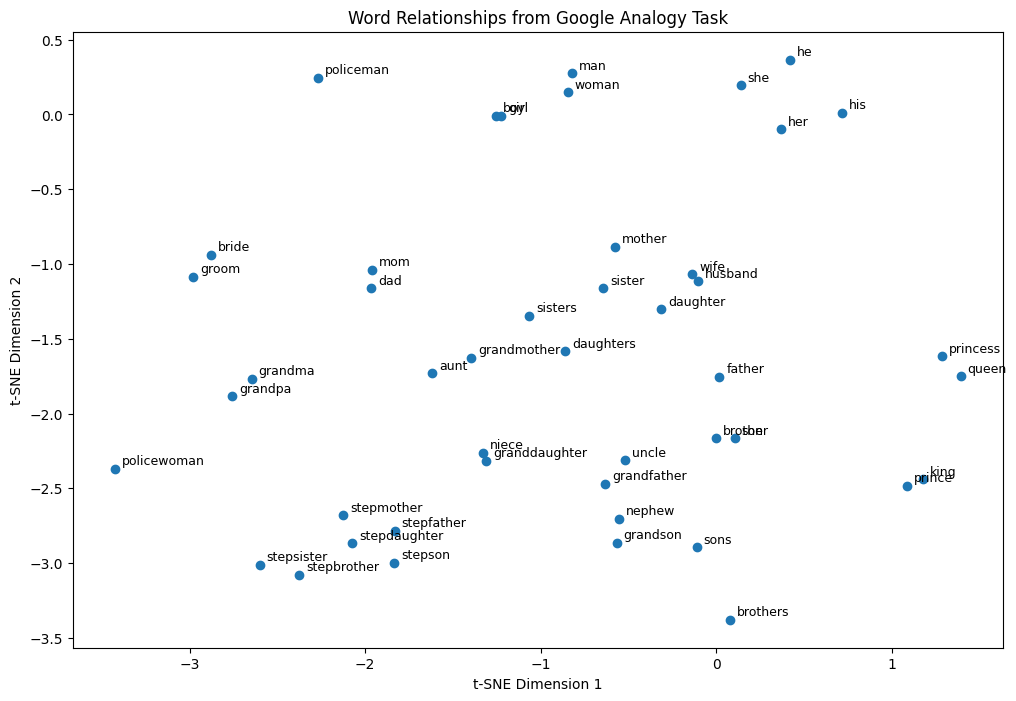

<Figure size 640x480 with 0 Axes>

In [ ]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO3: Plot t-SNE for the words in the SUB_CATEGORY `: family`
#Generative AI usage:
# ChatGPT was consulted about choosing a valid t-SNE perplexity
# and filtering words that were not available in the model.
# I checked the visualization and retained the required sample code.
subcategory_name = SUB_CATEGORY.strip()
family_questions = data.loc[
    data["SubCategory"] == subcategory_name, "Question"
]

words = list(dict.fromkeys(
    word
    for question in family_questions
    for word in question.lower().split()
))

words = [word for word in words if word in model]

if len(words) < 2:
    raise ValueError("可用單字不足，請確認 family 資料與模型已載入。")


vectors = np.array([model[word] for word in words])


tsne = TSNE(
    n_components=2,
    perplexity=min(30, len(words) - 1),
    init="random",
    random_state=42
)
coordinates = tsne.fit_transform(vectors)


plt.figure(figsize=(12, 8))
plt.scatter(coordinates[:, 0], coordinates[:, 1])


for word, (x, y) in zip(words, coordinates):
    plt.annotate(
        word,
        (x, y),
        xytext=(5, 3),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

### Part III: Train your own word embeddings

### Get the latest English Wikipedia articles and do sampling.
- Usually, we start from Wikipedia dump (https://dumps.wikimedia.org/enwiki/latest/enwiki-latest-pages-articles.xml.bz2). However, the downloading step will take very long. Also, the cleaning step for the Wikipedia corpus ([`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus)) will take much time. Therefore, we provide cleaned files for you.

In [ ]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles).
# 因在本地端執行這段可以跳過
!gdown --id 1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd -O wiki_texts_part_0.txt.gz
!gdown --id 1ABblLRd9HXdXvaNv8H9fFq984bhnowoG -O wiki_texts_part_1.txt.gz
!gdown --id 1z2VFNhpPvCejTP5zyejzKj5YjI_Bn42M -O wiki_texts_part_2.txt.gz
!gdown --id 1VKjded9BxADRhIoCzXy_W8uzVOTWIf0g -O wiki_texts_part_3.txt.gz
!gdown --id 16mBeG26m9LzHXdPe8UrijUIc6sHxhknz -O wiki_texts_part_4.txt.gz

In [ ]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles), except the last file.
# 因在本地端執行這段可以跳過
!gdown --id 17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI -O wiki_texts_part_5.txt.gz
!gdown --id 19IvB2vOJRGlrYulnTXlZECR8zT5v550P -O wiki_texts_part_6.txt.gz
!gdown --id 1sjwO8A2SDOKruv6-8NEq7pEIuQ50ygVV -O wiki_texts_part_7.txt.gz
!gdown --id 1s7xKWJmyk98Jbq6Fi1scrHy7fr_ellUX -O wiki_texts_part_8.txt.gz
!gdown --id 17eQXcrvY1cfpKelLbP2BhQKrljnFNykr -O wiki_texts_part_9.txt.gz
!gdown --id 1J5TAN6bNBiSgTIYiPwzmABvGhAF58h62 -O wiki_texts_part_10.txt.gz

In [ ]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles).
# 本機執行，將檔案從投影片的 LINK 下載並解壓到 wiki_texts/ 資料夾
# 因自身電腦效能較差，因此借用同學電腦執行導致檔案的路徑可能會雷同
!mv wiki_texts/wiki_texts_part_*.txt.gz .
!ls -lh wiki_texts_part_*.gz

zsh:1: no matches found: wiki_texts/wiki_texts_part_*.txt.gz
-rw-r--r--@ 1 panshihwei  staff   1.4G Sep 10  2025 wiki_texts_part_0.txt.gz
-rw-r--r--@ 1 panshihwei  staff   798M Sep 10  2025 wiki_texts_part_1.txt.gz
-rw-r--r--@ 1 panshihwei  staff   2.8K Sep 10  2025 wiki_texts_part_10.txt.gz
-rw-r--r--@ 1 panshihwei  staff   634M Sep 10  2025 wiki_texts_part_2.txt.gz
-rw-r--r--@ 1 panshihwei  staff   568M Sep 10  2025 wiki_texts_part_3.txt.gz
-rw-r--r--@ 1 panshihwei  staff   542M Sep 10  2025 wiki_texts_part_4.txt.gz
-rw-r--r--@ 1 panshihwei  staff   552M Sep 10  2025 wiki_texts_part_5.txt.gz
-rw-r--r--@ 1 panshihwei  staff   529M Sep 10  2025 wiki_texts_part_6.txt.gz
-rw-r--r--@ 1 panshihwei  staff   505M Sep 10  2025 wiki_texts_part_7.txt.gz
-rw-r--r--@ 1 panshihwei  staff   524M Sep 10  2025 wiki_texts_part_8.txt.gz
-rw-r--r--@ 1 panshihwei  staff   521M Sep 10  2025 wiki_texts_part_9.txt.gz


In [ ]:
# Extract the downloaded wiki_texts_parts files.
!gunzip -k wiki_texts_part_*.gz

In [ ]:
# Combine the extracted wiki_texts_parts files.
!cat wiki_texts_part_*.txt > wiki_texts_combined.txt

cat: stdout: No space left on device


In [ ]:
# Check the first ten lines of the combined file
!head -n 10 wiki_texts_combined.txt

anarchism is political philosophy and movement that is against all forms of authority and seeks to abolish the institutions it claims maintain unnecessary coercion and hierarchy typically including the state and capitalism anarchism advocates for the replacement of the state with stateless societies and voluntary free associations as historically left wing movement this reading of anarchism is placed on the farthest left of the political spectrum usually described as the libertarian wing of the socialist movement libertarian socialism although traces of anarchist ideas are found all throughout history modern anarchism emerged from the enlightenment during the latter half of the th and the first decades of the th century the anarchist movement flourished in most parts of the world and had significant role in workers struggles for emancipation various anarchist schools of thought formed during this period anarchists have taken part in several revolutions most notably in the paris commune

Please note that we used the default parameters of [`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus) for cleaning the Wiki raw file. Thus, words with one character were discarded.

In [ ]:
output_path = "wiki_texts_sampled.txt"

In [ ]:
#set checkpoint to verify the combined file exist
import os

combined_path = "wiki_texts_combined.txt"

print("合併檔是否存在：", os.path.exists(combined_path))

if os.path.exists(combined_path):
    size_gb = os.path.getsize(combined_path) / (1024 ** 3)
    print(f"合併檔大小：{size_gb:.2f} GB")

合併檔是否存在： True
合併檔大小：12.96 GB


In [ ]:
# Now you need to do sampling because the corpus is too big.
# You can further perform analysis with a greater sampling ratio.

import random

wiki_txt_path = "wiki_texts_combined.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # TODO4: Sample `20%` Wikipedia articles
    # Write your code here
     random.seed(123)

     for line in f:
          if random.random() < 0.2:
              output_file.write(line)

In [ ]:
# TODO5: Train your own word embeddings with the sampled articles
# https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec
# Hint: You should perform some pre-processing before training.
# Chatgpt usage to design a streaming corpus iterator
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess


class ProcessedWikipediaCorpus:
    def __init__(self, file_path):
        self.file_path = file_path

    def __iter__(self):
        with open(
            self.file_path,
            "r",
            encoding="utf-8"
        ) as f:
            for line in f:
                words = simple_preprocess(
                    line,
                    deacc=True,
                    min_len=2,
                    max_len=30
                )

                if words:
                    yield words


sentences = ProcessedWikipediaCorpus(output_path)

model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    workers=2,
    sg=0,
    epochs=5,
    seed=123
)

print("Word2Vec training completed.")
print("Vocabulary size:", len(model.wv))

Word2Vec training completed.
Vocabulary size: 764978


In [ ]:
#Chatgpt usage to save the model
from pathlib import Path

model_dir = Path("checkpoints")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = (
    model_dir / "wikipedia_20pct_word2vec.model"
)

model.save(str(model_path))

print("模型儲存完成")
print("儲存位置：", model_path)

模型儲存完成
儲存位置： checkpoints/wikipedia_20pct_word2vec.model


In [ ]:
data = pd.read_csv("questions-words.csv")

In [ ]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO6: Write your code here to use your trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      word_a, word_b, word_c, word_d = analogy.lower().split()


      golds.append(word_d)


      if all(word in model.wv for word in [word_a, word_b, word_c]):
          result = model.wv.most_similar(
              positive=[word_b, word_c],
              negative=[word_a],
              topn=1
          )
          preds.append(result[0][0])
      else:
          preds.append("")

100%|██████████| 19544/19544 [04:07<00:00, 78.89it/s] 


Words used in TODO7: ['boy', 'girl', 'brother', 'sister', 'brothers', 'sisters', 'dad', 'mom', 'father', 'mother', 'grandfather', 'grandmother', 'grandpa', 'grandma', 'grandson', 'granddaughter', 'groom', 'bride', 'he', 'she', 'his', 'her', 'husband', 'wife', 'king', 'queen', 'man', 'woman', 'nephew', 'niece', 'policeman', 'policewoman', 'prince', 'princess', 'son', 'daughter', 'sons', 'daughters', 'stepbrother', 'stepsister', 'stepfather', 'stepmother', 'stepson', 'stepdaughter', 'uncle', 'aunt']
Number of words: 46


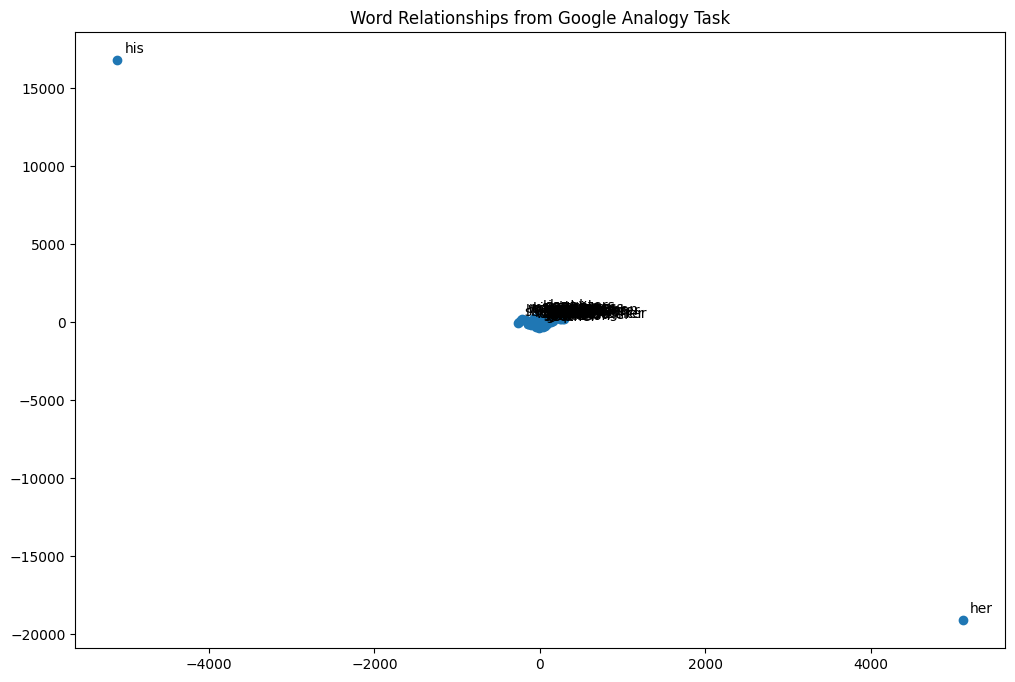

<Figure size 640x480 with 0 Axes>

In [ ]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO7: Plot t-SNE for the words in the SUB_CATEGORY `: family`
# ChatGPT was consulted about selecting a valid t-SNE perplexity
words = [
    word
    for word in words
    if word in model.wv
]

print("Words used in TODO7:", words)
print("Number of words:", len(words))

if len(words) < 3:
    raise ValueError(
        "Not enough family words are available in "
        "the trained Word2Vec model."
    )


word_vectors = np.array([
    model.wv[word]
    for word in words
])

tsne = TSNE(
    n_components=2,
    perplexity=min(5, len(words) - 1),
    init="random",
    learning_rate=200.0,
    random_state=123
)

word_vectors_2d = tsne.fit_transform(
    word_vectors
)


plt.figure(figsize=(12, 8))

plt.scatter(
    word_vectors_2d[:, 0],
    word_vectors_2d[:, 1]
)

for word, coordinate in zip(
    words,
    word_vectors_2d
):
    x, y = coordinate

    plt.annotate(
        word,
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Word Relationships from Google Analogy Task")
plt.show()
plt.savefig("word_relationships.png", bbox_inches="tight")

Running environment: **System:Local Jupyter Notebook (macOS) CPU:**
          

Python version: **3.10.2**

##### 1. Which embedding model do you use? What are the pre-processing steps? What are the hyperparameter settings? (5%)

Answer:

- **Embedding models**
  - In Part II, I used Gensim's pre-trained \`glove-wiki-gigaword-100\` model. It contains 100-dimensional GloVe vectors trained on Wikipedia and Gigaword.
  - In Part III, I trained Word2Vec models with the CBOW architecture on 5%, 10%, and 20% samples of the provided English Wikipedia corpus. The 20% model was used as the main self-trained model.
- **Wikipedia sampling**
  - Wikipedia articles were sampled independently, and \`random.seed(123)\` was used for reproducibility.
  - The completed samples contained 162,921 articles (5%), 325,843 articles (10%), and 652,322 articles (20%).
- **Pre-processing**
  - The corpus was processed one article at a time with a streaming iterable to avoid loading the complete corpus into memory.
  - Gensim's \`simple_preprocess\` was used with \`deacc=True\`, \`min_len=2\`, and \`max_len=30\`.
  - This converted text to lowercase, removed punctuation and accent marks, retained alphabetic tokens between 2 and 30 characters, and skipped empty articles.
- **Word2Vec hyperparameters**
  - Architecture: CBOW (\`sg=0\`)
  - \`vector_size=100\`
  - \`window=5\`
  - \`min_count=5\`
  - \`workers=2\`
  - \`epochs=5\`
  - \`seed=123\`
  - The vector size was set to 100 to match the dimensionality of the pre-trained GloVe model.
- The Brown Corpus experiment used the same preprocessing procedure and Word2Vec hyperparameters, allowing the effect of corpus choice to be compared under consistent settings.

##### 2. What will the performance be like if you sample 5%, 10% and 20% of wiki text in TODO4? (10%, 3% for each)

Answer:

| Wikipedia sample | Category | Questions | Correct | Vocabulary size | Accuracy (%) | Coverage (%) | Covered accuracy (%) |
|---:|---|---:|---:|---:|---:|---:|---:|
| 5% | Overall | 19,544 | 9,916 | 322,312 | 50.74 | 99.83 | 50.82 |
| 5% | Semantic | 8,869 | 5,002 | 322,312 | 56.40 | 100.00 | 56.40 |
| 5% | Syntactic | 10,675 | 4,914 | 322,312 | 46.03 | 99.69 | 46.18 |
| 10% | Overall | 19,544 | 10,634 | 497,603 | 54.41 | 100.00 | 54.41 |
| 10% | Semantic | 8,869 | 5,339 | 497,603 | 60.20 | 100.00 | 60.20 |
| 10% | Syntactic | 10,675 | 5,295 | 497,603 | 49.60 | 100.00 | 49.60 |
| 20% | Overall | 19,544 | 11,196 | 764,978 | 57.29 | 100.00 | 57.29 |
| 20% | Semantic | 8,869 | 5,545 | 764,978 | 62.52 | 100.00 | 62.52 |
| 20% | Syntactic | 10,675 | 5,651 | 764,978 | 52.94 | 100.00 | 52.94 |

- Overall accuracy increased consistently from **50.74%** at 5%, to **54.41%** at 10%, and **57.29%** at 20%.
- Semantic accuracy increased from **56.40%** to **62.52%**, while syntactic accuracy increased from **46.03%** to **52.94%**.
- Vocabulary size increased from **322,312** to **764,978** words.
- Coverage was already 99.83% at 5% and reached 100% at 10%. Therefore, the improvement from 10% to 20% mainly resulted from better word representations rather than additional test-word coverage.
- The results show that more training data provides more contexts for each word and produces more stable embeddings. The smaller improvement at higher sampling ratios also suggests diminishing returns.

##### 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

###### 3.1. Present your results. (5%)

Answer:

**Overall results**

| Corpus | Questions | Covered | Correct | Accuracy (%) | Coverage (%) | Covered accuracy (%) |
|---|---:|---:|---:|---:|---:|---:|
| Brown Corpus | 19,544 | 7,533 | 173 | 0.89 | 38.54 | 2.30 |
| Wikipedia 20% | 19,544 | 19,544 | 11,196 | 57.29 | 100.00 | 57.29 |

**Semantic and syntactic results**

| Corpus | Category | Correct / Questions | Accuracy (%) | Coverage (%) | Covered accuracy (%) |
|---|---|---:|---:|---:|---:|
| Brown Corpus | Semantic | 55 / 8,869 | 0.62 | 10.82 | 5.73 |
| Brown Corpus | Syntactic | 118 / 10,675 | 1.11 | 61.57 | 1.80 |
| Wikipedia 20% | Semantic | 5,545 / 8,869 | 62.52 | 100.00 | 62.52 |
| Wikipedia 20% | Syntactic | 5,651 / 10,675 | 52.94 | 100.00 | 52.94 |

**Sub-category results**

| Sub-category | Brown accuracy (%) | Brown coverage (%) | Wikipedia 20% accuracy (%) |
|---|---:|---:|---:|
| capital-common-countries | 0.00 | 19.76 | 79.64 |
| capital-world | 0.00 | 1.66 | 75.24 |
| city-in-state | 0.04 | 18.52 | 50.10 |
| currency | 0.00 | 4.62 | 9.82 |
| family | 10.67 | 56.92 | 82.41 |
| adjective-to-adverb | 0.20 | 87.70 | 22.88 |
| opposite | 0.00 | 38.42 | 17.61 |
| comparative | 4.35 | 89.19 | 75.08 |
| superlative | 0.00 | 42.78 | 41.35 |
| present-participle | 1.14 | 71.40 | 44.89 |
| nationality-adjective | 0.00 | 20.76 | 85.05 |
| past-tense | 2.12 | 80.77 | 47.37 |
| plural | 0.53 | 64.86 | 56.76 |
| plural-verbs | 0.69 | 58.97 | 56.09 |

- Wikipedia 20% outperformed Brown in every sub-category.
- Wikipedia performed particularly well on \`nationality-adjective\` (85.05%), \`family\` (82.41%), \`capital-common-countries\` (79.64%), and \`comparative\` (75.08%).
- \`currency\` remained difficult even for Wikipedia, with an accuracy of 9.82%.
- Brown's best sub-category was \`family\`, but its accuracy was only 10.67%.

###### 3.2. Introduce the corpus you selected and explain the differences between the Wikipedia corpus and your corpus. (5%)

Answer:

- I selected the **Brown Corpus**, a classic balanced American English corpus containing genres such as news, editorials, fiction, reviews, religion, academic writing, government documents, and adventure stories.

| Corpus | Documents / training units | Training tokens | Vocabulary size |
|---|---:|---:|---:|
| Brown Corpus | 500 documents / 56,744 sentences | 981,351 | 13,779 |
| Wikipedia 20% | 652,322 articles | 450,284,548 | 764,978 |

- **Size:** Wikipedia 20% is substantially larger than Brown in both token count and vocabulary size.
- **Topic:** Brown aims to balance multiple writing genres, whereas Wikipedia contains extensive encyclopedic information about countries, cities, nationalities, history, science, culture, and technology. These topics closely match many Google Analogy questions.
- **Structure:** Brown was trained sentence by sentence. The Wikipedia corpus was organized by article, providing longer, topically coherent training units.
- **Time period:** Brown mainly represents earlier American English, whereas Wikipedia contains more modern terms, named entities, places, and technology-related vocabulary.

###### 3.3. Explain why the performance increases or decreases. (5%)

Answer:

- Wikipedia 20% contains about 450 million tokens, compared with fewer than one million in Brown. More observations provide richer contexts and more stable embeddings.
- Wikipedia reached 100% coverage, while Brown covered only 38.54% of all questions and 10.82% of semantic questions. Brown therefore could not answer many questions involving capitals, countries, cities, currencies, or nationalities.
- Wikipedia's encyclopedic domain is much closer to the content of the Google Analogy dataset.
- In Brown, rare words may occur too few times to learn reliable vectors or may be removed by \`min_count=5\`.
- Brown's syntactic coverage was higher than its semantic coverage because ordinary English text contains common grammatical forms. However, its covered accuracy remained low, showing that vocabulary presence alone does not guarantee an accurate vector relationship.

##### 4. Select a few words and use their embeddings to retrieve the five most similar words. What do you observe? (10%)

Answer:

| Query word | Five most similar words (cosine similarity) |
|---|---|
| king | prince (0.7787), queen (0.7532), monarch (0.6922), regent (0.6849), conqueror (0.6766) |
| computer | computers (0.7934), software (0.7814), computing (0.7586), mainframe (0.7585), minicomputer (0.7372) |
| country | nation (0.6935), australia (0.5649), countries (0.5612), europe (0.5603), us (0.5183) |
| music | jazz (0.7713), musical (0.7687), dance (0.7207), recording (0.6711), pop (0.6534) |
| school | schools (0.7720), college (0.7524), highschool (0.6486), prep (0.6407), shsm (0.6365) |

- The model learned clear semantic relationships. For example, \`king\` is close to royal terms, \`computer\` is close to computing terms, and \`music\` is close to genres and performance-related terms.
- It also learned morphological relationships such as \`computer/computers\`, \`country/countries\`, and \`school/schools\`.
- Similar words are not necessarily synonyms. For example, \`king\` and \`queen\` are different concepts but occur in similar contexts. Word2Vec therefore represents distributional similarity rather than dictionary equivalence.
- Less intuitive results such as \`shsm\` may reflect abbreviations, named entities, or noise specific to the training corpus.

##### 5. Anything that can strengthen your report. (5%)

Answer:
**Comparison with the pre-trained GloVe model**

| Model | Semantic accuracy (%) | Syntactic accuracy (%) |
|---|---:|---:|
| Pre-trained GloVe | 65.34 | 61.26 |
| Self-trained Wikipedia 20% Word2Vec | 62.52 | 52.94 |

- The pre-trained GloVe model performed better overall because it was trained on the larger Wikipedia and Gigaword corpora. The self-trained model was relatively close on semantic questions but showed a larger gap on syntactic questions.
- In addition to accuracy, I reported coverage and covered accuracy. This separates errors caused by missing vocabulary from incorrect predictions for covered questions.
- All 11 Wikipedia files were downloaded, extracted, and included before sampling. The three Wikipedia experiments used the same preprocessing, random seed, and Word2Vec settings.
##### 6. Generative AI Usage

Answer:

**Yes**

- I used ChatGPT to help diagnose Google Drive download and memory issues, design a streaming corpus iterator, organize the additional Brown Corpus experiment, select a valid t-SNE perplexity, filter out-of-vocabulary words, and improve the report structure.
- I reviewed and understood the generated code and verified it using the actual notebook outputs.
- All numerical results and figures in this report were produced by executing the notebook; they were not invented by generative AI.


## Code For 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

In [ ]:
%pip install -q nltk

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Write your code here
# Chatgpt usage to download the dataset
import nltk
from nltk.corpus import brown
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from pathlib import Path

nltk.download("brown")

[nltk_data] Downloading package brown to
[nltk_data]     /Users/panshihwei/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


True

In [ ]:
class ProcessedBrownCorpus:
    def __iter__(self):
        for sentence in brown.sents():
            text = " ".join(sentence)

            words = simple_preprocess(
                text,
                deacc=True,
                min_len=2,
                max_len=30
            )

            if words:
                yield words


brown_sentences = ProcessedBrownCorpus()

brown_model = Word2Vec(
    sentences=brown_sentences,
    vector_size=100,
    window=5,
    min_count=5,
    workers=2,
    sg=0,
    epochs=5,
    seed=123
)

print("Brown Word2Vec training completed.")
print("Brown vocabulary size:", len(brown_model.wv))

Brown Word2Vec training completed.
Brown vocabulary size: 13779


In [ ]:
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

brown_model_path = (
    model_dir / "brown_word2vec.model"
)

brown_model.save(str(brown_model_path))

print("Brown model saved to:", brown_model_path)

Brown model saved to: models/brown_word2vec.model


In [ ]:

import pandas as pd
import numpy as np
from tqdm.auto import tqdm


def evaluate_model(
    trained_model,
    questions_data,
    corpus_name
):
    predictions = []
    gold_answers = []
    covered_questions = []

    for analogy in tqdm(
        questions_data["Question"],
        desc=f"Evaluating {corpus_name}"
    ):
        word_a, word_b, word_c, word_d = (
            analogy.lower().split()
        )

        gold_answers.append(word_d)

        is_covered = all(
            word in trained_model.wv
            for word in [word_a, word_b, word_c]
        )

        covered_questions.append(is_covered)

        if is_covered:
            result = trained_model.wv.most_similar(
                positive=[word_b, word_c],
                negative=[word_a],
                topn=1
            )

            predictions.append(result[0][0])
        else:
            predictions.append("")

    result_data = questions_data.copy()

    result_data["Corpus"] = corpus_name
    result_data["Gold"] = gold_answers
    result_data["Prediction"] = predictions
    result_data["Covered"] = covered_questions
    result_data["Correct"] = (
        result_data["Gold"] ==
        result_data["Prediction"]
    )

    return result_data

/Users/panshihwei/Downloads/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:


import gc
from pathlib import Path
from gensim.models import Word2Vec

brown_model_path = Path(
    "models/brown_word2vec.model/"
)

wiki_model_path = Path(
    "checkpoints/wikipedia_20pct_word2vec.model/"
)

if not brown_model_path.exists():
    raise FileNotFoundError(
        f"Brown model not found: {brown_model_path}"
    )

if not wiki_model_path.exists():
    raise FileNotFoundError(
        f"Wikipedia model not found: {wiki_model_path}"
    )

all_corpus_evaluations = []

current_model = Word2Vec.load(
    str(brown_model_path)
)

brown_results = evaluate_model(
    current_model,
    data,
    "Brown Corpus"
)

all_corpus_evaluations.append(brown_results)

del current_model
gc.collect()

current_model = Word2Vec.load(
    str(wiki_model_path)
)

wiki_results = evaluate_model(
    current_model,
    data,
    "Wikipedia 20%"
)

all_corpus_evaluations.append(wiki_results)

del current_model
gc.collect()

corpus_evaluation = pd.concat(
    all_corpus_evaluations,
    ignore_index=True
)

print("Evaluation completed.")
print("Total result rows:", len(corpus_evaluation))

Evaluating Wikipedia 20%: 100%|██████████| 19544/19544 [04:01<00:00, 80.81it/s] 


Evaluation completed.
Total result rows: 39088


In [ ]:
# ChatGPT was consulted about organizing the evaluation metrics
def calculate_group_metrics(group):
    question_count = len(group)
    correct_count = int(group["Correct"].sum())
    covered_count = int(group["Covered"].sum())

    accuracy = (
        correct_count / question_count * 100
        if question_count > 0
        else np.nan
    )

    coverage = (
        covered_count / question_count * 100
        if question_count > 0
        else np.nan
    )

    covered_accuracy = (
        group.loc[
            group["Covered"],
            "Correct"
        ].mean() * 100
        if covered_count > 0
        else np.nan
    )

    return {
        "Questions": question_count,
        "Covered": covered_count,
        "Correct": correct_count,
        "Accuracy (%)": accuracy,
        "Coverage (%)": coverage,
        "Covered accuracy (%)": covered_accuracy
    }

In [ ]:

overall_rows = []

for corpus_name, group in corpus_evaluation.groupby(
    "Corpus"
):
    row = {
        "Corpus": corpus_name,
        **calculate_group_metrics(group)
    }

    overall_rows.append(row)

overall_corpus_results = pd.DataFrame(
    overall_rows
)

print("Overall results")
display(overall_corpus_results.round(2))

Overall results


,Corpus,Questions,Covered,Correct,Accuracy (%),Coverage (%),Covered accuracy (%)
0,Brown Corpus,19544,7533,173,0.89,38.54,2.30
1,Wikipedia 20%,19544,19544,11196,57.29,100.00,57.29


In [ ]:
subcategory_rows = []

for (
    corpus_name,
    subcategory_name
), group in corpus_evaluation.groupby(
    ["Corpus", "SubCategory"]
):
    row = {
        "Corpus": corpus_name,
        "SubCategory": subcategory_name,
        **calculate_group_metrics(group)
    }

    subcategory_rows.append(row)

subcategory_corpus_results = pd.DataFrame(
    subcategory_rows
)

print("SubCategory results")
display(subcategory_corpus_results.round(2))

SubCategory results


,Corpus,SubCategory,Questions,Covered,Correct,Accuracy (%),Coverage (%),Covered accuracy (%)
0,Brown Corpus,: capital-common-countries,506,100,0,0.00,19.76,0.00
1,Brown Corpus,: capital-world,4524,75,0,0.00,1.66,0.00
2,Brown Corpus,: city-in-state,2467,457,1,0.04,18.52,0.22
3,Brown Corpus,: currency,866,40,0,0.00,4.62,0.00
4,Brown Corpus,: family,506,288,54,10.67,56.92,18.75
5,Brown Corpus,: gram1-adjective-to-adverb,992,870,2,0.20,87.70,0.23
6,Brown Corpus,: gram2-opposite,812,312,0,0.00,38.42,0.00
7,Brown Corpus,: gram3-comparative,1332,1188,58,4.35,89.19,4.88
8,Brown Corpus,: gram4-superlative,1122,480,0,0.00,42.78,0.00
9,Brown Corpus,: gram5-present-participle,1056,754,12,1.14,71.40,1.59


In [ ]:
# ChatGPT was consulted about loading the saved Word2Vec models
from nltk.corpus import brown
from gensim.models import Word2Vec

brown_statistics_model = Word2Vec.load(
    str(brown_model_path)
)

wiki_statistics_model = Word2Vec.load(
    str(wiki_model_path)
)

corpus_statistics = pd.DataFrame([
    {
        "Corpus": "Brown Corpus",
        "Documents": len(brown.fileids()),
        "Training units": (
            brown_statistics_model.corpus_count
        ),
        "Training unit type": "Sentence",
        "Training tokens": (
            brown_statistics_model.corpus_total_words
        ),
        "Vocabulary size": (
            len(brown_statistics_model.wv)
        )
    },
    {
        "Corpus": "Wikipedia 20%",
        "Documents": (
            wiki_statistics_model.corpus_count
        ),
        "Training units": (
            wiki_statistics_model.corpus_count
        ),
        "Training unit type": "Article",
        "Training tokens": (
            wiki_statistics_model.corpus_total_words
        ),
        "Vocabulary size": (
            len(wiki_statistics_model.wv)
        )
    }
])

display(corpus_statistics)

del brown_statistics_model
del wiki_statistics_model
gc.collect()

,Corpus,Documents,Training units,Training unit type,Training tokens,Vocabulary size
0,Brown Corpus,500,56744,Sentence,981351,13779
1,Wikipedia 20%,652322,652322,Article,450284548,764978


22

In [ ]:
#Report question4
from gensim.models import Word2Vec

wiki_model = Word2Vec.load(
    "checkpoints/wikipedia_20pct_word2vec.model"
)

selected_words = [
    "king",
    "computer",
    "country",
    "music",
    "school"
]

for word in selected_words:
    print(f"\nQuery word: {word}")

    if word in wiki_model.wv:
        results = wiki_model.wv.most_similar(
            word,
            topn=5
        )

        for rank, (similar_word, score) in enumerate(
            results,
            start=1
        ):
            print(
                f"{rank}. {similar_word}: "
                f"{score:.4f}"
            )
    else:
        print("This word is not in the vocabulary.")


Query word: king
1. prince: 0.7787
2. queen: 0.7532
3. monarch: 0.6922
4. regent: 0.6849
5. conqueror: 0.6766

Query word: computer
1. computers: 0.7934
2. software: 0.7814
3. computing: 0.7586
4. mainframe: 0.7585
5. minicomputer: 0.7372

Query word: country
1. nation: 0.6935
2. australia: 0.5649
3. countries: 0.5612
4. europe: 0.5603
5. us: 0.5183

Query word: music
1. jazz: 0.7713
2. musical: 0.7687
3. dance: 0.7207
4. recording: 0.6711
5. pop: 0.6534

Query word: school
1. schools: 0.7720
2. college: 0.7524
3. highschool: 0.6486
4. prep: 0.6407
5. shsm: 0.6365
